- do the gradient + fourier transform method

In [ ]:
# import statements

import PyPhenom as ppi
import numpy as np
import matplotlib.pyplot as plt
import cv2

from math import factorial
from scipy.fft import fft2, fftshift
from scipy.signal import fftconvolve
from scipy.spatial.distance import pdist, squareform
from lmfit import Model, create_params
from skopt import gp_minimize

%matplotlib widget


In [ ]:
# connects to SEM 

PhenomID = 'MVE086101-20057-F'
username = 'MVE08610120057F'
password = 'KN68X6HJQMT9'

phenom = ppi.Phenom(PhenomID, username, password)

In [ ]:
# misc helper function

def take_image(xdim = 256, ydim = 256, stack = 4, HDR = False, scale = 0.5 ):
    """
    Takes an image of the current location shown on the SEM and returns the image array
    and the pixel dimensions (width and height) in meters.
    """
    #Set to a value < 1 to zoom in on a part of the image - centered # change to less than 1, .5 maybe?

    # phenom.SemAutoContrastBrightness()
    acq = phenom.SemAcquireImage(xdim, ydim, stack, ppi.DetectorMode.All, HDR, scale)

    img_array = np.array(acq.image) # converts image into an array

    return img_array, acq.metadata

In [ ]:
def kuwahara(orig_img, method='mean', radius=3, sigma=None, grayconv=cv2.COLOR_BGR2GRAY, image_2d=None):
    """
    Get the image filtered with Kuwahara method.

    :param orig_img: original numpy image (support multichannel)
    :type orig_img: :class:`numpy.ndarray`
    :param method: method used to compute the pixels values
    :type method: "gaussian" | "mean"
    :param radius: the window radius (`winsize = 2 * radius + 1`)
    :type radius: `int`
    :param sigma: the sigma used if metod is "gaussian", automatically computed by OpenCV when `None`
    :type sigma: `float` or `None`
    :param grayconv: The OpenCV conversion code to extract grayscale image from `orig_img` (default `COLOR_BGR2GRAY`)
    :type grayconv: `int`
    :param image_2d: The 1-channel image used to compute the variance, if provided instead of `grayconv`
    :type image_2d: `numpy.ndarray`
    :returns: the filtered image
    :rtype: `numpy.ndarray`
    """

    pass

In [ ]:
# calibration functions part 1

def calibrate_kernel_size(wd_val_min):
    """
    Returns the kernel size used to apply a blur to the images taken while focusing the SEM.

    Parameter wd_val_min: the minimum working distance (float) that the SEM can image at
    """

    sums = -1
    kernel_size = 5

    phenom.SetSemStigmate(ppi.Position(0, 0)) # sets the stigmate to (0, 0) for sort of optimized stig
    phenom.SetHFW(ppi.MagnificationToFieldWidth(10000, 0.52)) # sets magnification to 10000
    phenom.SetSemWD(wd_val_min) # sets the working distance to wd_val_min

    img_array, _ = take_image() # takes image of current location

    while np.round(sums, 4) != 0:
        blurred_img = cv2.GaussianBlur(img_array, (kernel_size, kernel_size), 0) # blurs the image
        filtered_data = cv2.Canny(blurred_img, 50, 150) # applies a canny filter to the blurred image

        sums = filtered_data.sum() # sums up the pixel values in the filtered image
        
        if np.round(sums, 4) != 0: # if the sum is not 0, add 2 to the kernel size and repeat
            kernel_size = kernel_size + 2

    return kernel_size


In [ ]:
# global variables
wd_val_min = 0.002 #0.008 #0.002
wd_val_max = 0.012 #0.011 #0.025 #0.12198 is max value
xst_val_min = -0.05 #-1
xst_val_max = 0.05 #1
yst_val_min = -0.05 #-1
yst_val_max = 0.05 #1


In [ ]:
size = calibrate_kernel_size(wd_val_min)

In [ ]:
# autocorrelation functions

def auto_correlation(frame):
    """
    Returns the computed auto_correlation for a given frame.

    Parameter frame: a Numpy array representing an SEM image
    """

    ft = np.fft.fft2(frame)
    autocorr = np.fft.ifft2(ft * np.conjugate(ft))
    return np.fft.fftshift(autocorr).real


def filtered_autocorr(img_array, kernel_size):
    """
    Returns the autocorrelation array for the given image array after applying a blur 
    (given the blurring kernel kernel_size) and a canny filter to img_array.

    Parameter img_array: a Numpy array representing an image
    Parameter kernel_size: an int specifying the size of the blurring kernel
    """

    # converted_img2 = cv2.cvtColor(img_array, cv2.COLOR_GRAY2BGR)
    # # denoised_img2 = kuwahara(converted_img2, method = 'gaussian', sigma = 1)
    # denoised_img2 = cv2.fastNlMeansDenoisingColored(converted_img2, None, 10, 10, 7, 21)
    # gray_image2 = cv2.cvtColor(denoised_img2, cv2.COLOR_BGR2GRAY)
    # gaussian21 = cv2.GaussianBlur(gray_image2, (3, 3), 0)
    # clahe2 = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(16, 16))
    # equalized_img2 = clahe2.apply(gaussian21)
    # gaussian22 = cv2.GaussianBlur(equalized_img2, (9, 9), 0)
    # filtered_data = cv2.Canny(gaussian22, 50, 150)
    
    blurred_img = cv2.GaussianBlur(img_array, (kernel_size, kernel_size), 0) # blurs the image
    filtered_data = cv2.Canny(blurred_img, 50, 150) # sets the values of edges = 255, everything else = 0
    acdata = auto_correlation(filtered_data) # calculates the auto_correlation data

    return acdata


def remove_background_autocorr(acdata):
    """
    Returns the normalized autocorrelation with the background removed.

    Parameter acdata: a 2D Numpy array of the autocorrelation of an image
    """
    grad2_y = np.gradient(np.gradient(acdata[:, 128]))
    grad2_x = np.gradient(np.gradient(acdata[128, :]))

    x_first_half = grad2_x[:grad2_x.shape[0] // 2]
    x_last_half = grad2_x[grad2_x.shape[0] // 2:]
    y_first_half = grad2_y[:grad2_y.shape[0] // 2]
    y_last_half = grad2_y[grad2_y.shape[0] // 2:]

    x_first_max = np.argmax(x_first_half)
    x_last_max = np.argmax(x_last_half)
    y_first_max = np.argmax(y_first_half)
    y_last_max = np.argmax(y_last_half)

    x_first_cut = np.gradient(acdata[acdata.shape[0] // 2, :x_first_max])
    x_last_cut = np.gradient(acdata[acdata.shape[0] // 2, x_last_max + grad2_x.shape[0] // 2:])
    y_first_cut = np.gradient(acdata[:y_first_max, acdata.shape[1] // 2])
    y_last_cut = np.gradient(acdata[y_last_max + grad2_y.shape[0] // 2:, acdata.shape[1] // 2])

    x_first_min = np.argmax(x_first_cut)
    x_last_min = np.argmin(x_last_cut)
    y_first_min = np.argmax(y_first_cut)
    y_last_min = np.argmin(y_last_cut)

    # look into forecasting if this works
    extrapolate_first_x = np.gradient(acdata[:x_first_max, acdata.shape[1] // 2])[-2]
    for px in range(acdata.shape[0] // 2 - x_first_max):
        acdata[px + x_first_max, acdata.shape[1] // 2] = (extrapolate_first_x + 
                                                          acdata[px + x_first_max - 1, 
                                                                 acdata.shape[1] // 2])

    extrapolate_last_x = np.gradient(acdata[x_last_max + acdata.shape[0] // 2:, acdata.shape[1] // 2])[1]
    for px in range(x_last_max):
        acdata[px + acdata.shape[0] // 2, acdata.shape[1] // 2] = (extrapolate_last_x + 
                                                                   acdata[px + acdata.shape[0] // 2 - 1, 
                                                                          acdata.shape[1] // 2])

    extrapolate_first_y = np.gradient(acdata[acdata.shape[0] // 2, :y_first_max])[-2]
    for px in range(acdata.shape[1] // 2 - y_first_max):
        acdata[px + y_first_max, acdata.shape[1] // 2] = (extrapolate_first_y + 
                                                          acdata[px + y_first_max - 1, 
                                                                 acdata.shape[1] // 2])

    extrapolate_last_y = np.gradient(acdata[acdata.shape[0] // 2, y_last_max + acdata.shape[1] // 2:])[1]
    for px in range(y_last_max):
        acdata[acdata.shape[0] // 2, px + acdata.shape[1] // 2] = (extrapolate_last_y + 
                                                                   acdata[acdata.shape[1] // 2, 
                                                                          px + acdata.shape[1] // 2 - 1])
        
    threshold = acdata[x_first_min, y_first_min]

    for i in range(acdata.shape[0]):
        for j in range(acdata.shape[1]):
            if (i >= y_first_min - round((grad2_y.shape[0] // 2 - y_first_min) * 0.3) and 
                i <= y_last_min + grad2_y.shape[0] // 2  + round(y_last_min * 0.3) and 
                j >= x_first_min - round((grad2_x.shape[0] // 2 - x_first_min) * 0.3) and 
                j <= x_last_min + grad2_x.shape[0] // 2 + round(x_last_min * 0.3)):
                acdata[i][j] = acdata[i][j]
            else:
                acdata[i][j] = threshold

    for r in range(acdata.shape[0]):
        for c in range(acdata.shape[1]): # substracts either the threshold or img_array value, whichever is smaller
            acdata[r][c] = acdata[r][c] - min(threshold, acdata[r][c]) # from every point in img_array

    acdata = acdata / acdata.sum() # normalizes the data

    return acdata

In [ ]:
img_array, _ = take_image()
ac = auto_correlation(img_array)
removed = remove_background_autocorr(ac)
result = incoh_psf_fit(removed, 1, 1, 1)

In [ ]:
plt.figure()
plt.imshow(img_array)
plt.figure()
plt.imshow(ac)
plt.figure()
plt.imshow(removed)
plt.figure()
plt.imshow(result.best_fit)

In [ ]:
img_array, _ = take_image()

converted_img2 = cv2.cvtColor(img_array, cv2.COLOR_GRAY2BGR)
# denoised_img2 = kuwahara(converted_img2, method = 'gaussian', sigma = 1)
denoised_img2 = cv2.fastNlMeansDenoisingColored(converted_img2, None, 10, 10, 7, 21)
gray_image2 = cv2.cvtColor(denoised_img2, cv2.COLOR_BGR2GRAY)
gaussian21 = cv2.GaussianBlur(gray_image2, (3, 3), 0)
clahe2 = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(16, 16))
equalized_img2 = clahe2.apply(gaussian21)
gaussian22 = cv2.GaussianBlur(equalized_img2, (9, 9), 0)
filtered2 = cv2.Canny(gaussian22, 50, 150)

plt.figure(figsize=(10,5))
plt.subplot(161), plt.imshow(img_array)
plt.subplot(162), plt.imshow(denoised_img2)
plt.subplot(163), plt.imshow(gaussian21)
plt.subplot(164), plt.imshow(equalized_img2)
plt.subplot(165), plt.imshow(gaussian22)
plt.subplot(166), plt.imshow(filtered2)

In [ ]:
# calibration functions part 2

def reposition(kernel_size = size):
    """
    Repositions the SEM so that there is a feature in the center of the imaged location.
    """

    img_array, width, height = take_image() # takes picture of current location
    blurred_img = cv2.GaussianBlur(img_array, (kernel_size, kernel_size), 0) # blurs the image array
    filtered = cv2.Canny(blurred_img, 50, 150) # applies a canny filter

    # calculates the distance between each edge pixel in the filtered image and the other edge pixels
    points = [(i, j) for i, row in enumerate(filtered) for j, val in enumerate(row) if val == 255]
    distances = squareform(pdist(points, metric='euclidean'))
    total_distances = [sum(row) for row in distances]

    # selects the pixel with the smalleset distance between other pixels
    new_center = (points[np.argmin(total_distances)][1], points[np.argmin(total_distances)][0])

    # moves to the new center
    center = (img_array.shape[0] // 2, img_array.shape[1] // 2)
    px_distance = [center[0] - new_center[0], center[1] - new_center[1]]
    m_distance = [px_distance[0] * width, px_distance[1] * height]
    phenom.MoveBy(-1 * m_distance[0], m_distance[1])


from skimage import data
from skimage.util import img_as_ubyte
from skimage.filters.rank import entropy
from skimage.morphology import disk

def reposition_v2():
    img_array, meta = take_image() # takes picture of current location
    entropy_filtered = entropy(img_array, disk(5)) # calculates the entropy

    flat_index = np.argmax(entropy_filtered)
    y, x = np.unravel_index(flat_index, entropy_filtered.shape)
    new_center = (x, y)

    # moves to the new center
    center = (img_array.shape[0] // 2, img_array.shape[1] // 2)
    px_distance = [center[0] - new_center[0], center[1] - new_center[1]]
    m_distance = [px_distance[0] * meta.pixelSize.width, px_distance[1] * meta.pixelSize.height]
    phenom.MoveBy(-1 * m_distance[0], m_distance[1])

    fig, (ax0, ax1) = plt.subplots(ncols=2, sharex=True, sharey=True)
    img0 = ax0.imshow(img_array, cmap=plt.cm.gray)
    ax0.set_title("Image")
    ax0.axis("off")
    fig.colorbar(img0, ax=ax0)
    img1 = ax1.imshow(entropy_filtered, cmap='gray')
    ax1.set_title("Entropy")
    ax1.axis("off")
    fig.colorbar(img1, ax=ax1)
    fig.tight_layout()
    plt.show()

    specific_keypoint = cv2.KeyPoint(x=int(x), y=int(y), size=10, angle=0, response=0, octave=0, class_id=0)
    keypoints_to_draw = [specific_keypoint]

    img3 = cv2.drawKeypoints(img_array, keypoints_to_draw, None, color=(0,255,0), flags=0)
    plt.figure()
    plt.imshow(img3), plt.show()


def pixelposition(img, meta, xix, yix, ratio):
    """
    Obtain position on stage for pixel with index xix, yix in image img
    note that ratio > 1 the ratio HFW_old/HFW_new still has to be set
    Returns:
        Position object

    Afterwards: 
        phenom.MoveTo(pixelposition(img, meta, xix, yix))
        phenom.SetHFW(phenom.GetHFW()/ratio)
    """
    xpix = xix
    ypix = img.shape[1] - yix

    x, y = meta.position.x, meta.position.y

    x_size = img.shape[0]/ratio
    y_size = img.shape[1]/ratio

    xnew = x + (xpix + x_size//2 - img.shape[0] // 2) * meta.pixelSize.width
    ynew = y + (ypix - y_size//2 - img.shape[1] // 2) * meta.pixelSize.height

    return ppi.Position(xnew, ynew)


def find_ac_position(img, meta, x_size = 64, y_size = 64):
    acdata = np.zeros((img.shape[0]-x_size+1, img.shape[1]-y_size+1, x_size, y_size))

    for i in range(0, img.shape[0]-x_size+1):
        for j in range(0, img.shape[1]-y_size+1):
            window = img[i:i+x_size,j:j+y_size] # each individual window
            # result = filtered_autocorr(window, 9)
            result = auto_correlation(window)
            acdata[i, j] = result

    xix, yix = np.unravel_index(np.argmin(acdata.sum(axis=(2,3))), acdata.shape[:2])
    ratio = img.shape[0] / x_size
    return (xix, yix), pixelposition(img, meta, xix, yix, ratio), ratio, acdata


In [ ]:
# fitting functions

# Define basic Zernike polynomials (on the unit disk)
def zernike_radial(n, m, rho):
    R = np.zeros_like(rho)
    for k in range((n - abs(m)) // 2 + 1):
        coeff = (-1)**k * factorial(n - k)
        coeff /= (factorial(k) *
                  factorial((n + abs(m)) // 2 - k) *
                  factorial((n - abs(m)) // 2 - k))
        R += coeff * rho**(n - 2 * k)
    return R


def zernike(n, m, rho, theta):
    if m > 0:
        return zernike_radial(n, m, rho) * np.cos(m * theta)
    elif m < 0:
        return zernike_radial(n, -m, rho) * np.sin(-m * theta)
    else:
        return zernike_radial(n, 0, rho)


# Mapping Noll index to (n, m)
NOLL_MAP = {
    1:  (0,  0),   # Piston (constant phase offset)
    2:  (1, -1),   # Tilt X (Tip)
    3:  (1,  1),   # Tilt Y (Tilt)
    4:  (2, -2),   # Oblique Astigmatism
    5:  (2,  0),   # Defocus
    6:  (2,  2),   # Vertical Astigmatism
    7:  (3, -3),   # Vertical Trefoil
    8:  (3, -1),   # Vertical Coma
    9:  (3,  1),   # Horizontal Coma
    10: (3,  3),   # Horizontal Trefoil
    11: (4, -4),   # Oblique Tetrafoil
    12: (4, -2),   # Oblique Secondary Astigmatism
    13: (4,  0),   # Primary Spherical Aberration
    14: (4,  2),   # Vertical Secondary Astigmatism
    15: (4,  4),   # Vertical Tetrafoil
}


def incoherent_zernike_psf(N=256, defocus = None, xstig = None, ystig = None): # zernike_coeffs=None):
    if defocus is None: # if zernike_coeffs is None:
        zernike_coeffs = {
            5:2,  # defocus
        }

    else:
        zernike_coeffs = {
            5:defocus
        }

    if xstig is not None:
        zernike_coeffs[6] = xstig

    if ystig is not None:
        zernike_coeffs[4] = ystig

    x = np.linspace(- 1, 1, N)
    X, Y = np.meshgrid(x, x)
    rho = np.sqrt(X**2 + Y**2)
    theta = np.arctan2(Y, X)

    aperture = rho <= 1 #boolean array

    wavefront = np.zeros_like(rho)

    for j, coeff in zernike_coeffs.items():
        n, m = NOLL_MAP[j]
        Z = zernike(n, m, rho, theta)
        Z[~aperture] = 0
        wavefront += coeff * Z

    # Pupil function with aberration
    phase = 2 * np.pi * wavefront # this could be scaled by the wavelength.
    # suggest to not to do this in this case that adds to the confusion ==> this is not the same as a coherent point source!

    pupil = np.exp(1j * phase) 
    pupil[~aperture] = 0

    # Coherent PSF
    h = fftshift(fft2(pupil)) #The point spread function (PSF), which is given by the square of the absolute value of the 
    psf_coh = np.abs(h)**2    #Fourier transform of the wavefront, shows what the intensity image of a point source would look like.

    # Incoherent PSF: autocorrelation of coherent intensity
    psf_incoh = fftconvolve(psf_coh, psf_coh, mode='same')
    psf_incoh /= psf_incoh.sum()

    return psf_incoh


def incoh_psf_fit(ac, df, xst, yst):
    model = Model(incoherent_zernike_psf)

    pars = create_params(N = dict(value = 256, vary = False),
                         defocus = dict(value = df, vary = True, min = 0.1, max=5),
                         xstig = dict(value = xst, vary = True, min=-4, max=4),
                         ystig = dict(value = yst, vary = True, min=-4, max=4))

    result = model.fit(ac, params = pars) # uses the above parameters and  model to fit the data

    return result

In [ ]:
# optimization functions

def optimum_wd(wd, kernel_size = size):
    """
    Returns the negative sum of the autocorrelation values for the four pixels surrounding the 
    center pixel given wd, a list containing a working distance.
    This is the objective function to minimize the working distance.

    Parameter wd: a tuple containing an int or float specifying the working distance 
    Parameter kernel_size: an int specifying the size of the blurring kernel
    """

    phenom.SetSemWD(wd[0]) # sets the working distance to wd[0]

    if image_counter[0] % 10 == 0:
        phenom.SemAutoContrastBrightness()
    img_array, _ = take_image() # takes an image of the current location
    image_counter[0] += 1

    acdata = filtered_autocorr(img_array, kernel_size) # calculates the autocorrelation for the filtered image
    sums = (acdata[acdata.shape[0] // 2 - 1, acdata.shape[1] // 2] + 
            acdata[acdata.shape[0] // 2 + 1, acdata.shape[1] // 2] + 
            acdata[acdata.shape[0] // 2, acdata.shape[1] // 2 - 1] + 
            acdata[acdata.shape[0] // 2, acdata.shape[1] // 2 + 1]) # sums together the four center pixels
    
    return sums * (-1) # returns the negative of the sum


def auto_focus(wd_val_min, wd_val_max):
    """
    Determines the working distance corresponding to a focused image using bayesian optimization. 
    Sets the working distance to the value corresponding to a focused image after minimization.
    Returns the optimal working distance.

    Parameter wd_val_min: the minimum working distance (float) that is considered when minimizing
    Parameter wd_val_max: the maximum working distance (float) that is considered when minimizing
    """

    res = gp_minimize(optimum_wd, # calls scikit's bayesian optimization 
                      [(wd_val_min, wd_val_max)], 
                      acq_func = "EI", 
                      n_calls = 10, 
                      n_initial_points = 5, 
                      verbose = False, 
                      random_state = 1234) 

    phenom.SetSemWD(res.x[0]) # sets the working distance to the optimum
    return res.x[0]


def optimum_stig(st):
    """ 
    Returns the astigmatism coefficient of a Zernike polynomial fitted to the autocorrelation data
    at the given stigmate st.

    Parameter st: a tuple (x, y) for the x-stigmate and y-stigmate
    """

    xst, yst = st
    phenom.SetSemStigmate(ppi.Position(xst, yst))

    if image_counter[0] % 10 == 0:
        phenom.SemAutoContrastBrightness()
    img_array, _ = take_image() # takes an image of the current location
    image_counter[0] += 1

    acdata = auto_correlation(img_array) # calculates the autocorrelation for the image
    filtered_acdata = remove_background_autocorr(acdata) # removes the background of the autocorrelation

    result = incoh_psf_fit(filtered_acdata, 1, 1, 1) # fits the data

    plt.figure()
    plt.subplot(1, 3, 1)
    plt.imshow(acdata)
    plt.subplot(1, 3, 2)
    plt.imshow(filtered_acdata)
    plt.subplot(1, 3, 3)
    plt.imshow(result.best_fit)

    return np.sqrt(result.best_values['xstig'] ** 2 + result.best_values['ystig'] ** 2) #+ result.best_values['defocus']


def auto_stig(xst_val_min, xst_val_max, yst_val_min, yst_val_max):
    """
    Determines the stigmate values corresponding to a focused image using bayesian optimization. 
    Sets the working distance to the value corresponding to a focused image after minimization.

    Parameter xst_val_min: the minimum x-stigmate (float) that is considered when minimizing
    Parameter xst_val_max: the maximum x-stigmate distance (float) that is considered when minimizing
    Parameter yst_val_min: the minimum y-stigmate distance (float) that is considered when minimizing
    Parameter yst_val_max: the maximum y-stigmate distance (float) that is considered when minimizing
    """

    res = gp_minimize(optimum_stig, 
                      [(xst_val_min, xst_val_max), (yst_val_min, yst_val_max)], 
                      acq_func = "EI", 
                      n_calls = 20, 
                      n_initial_points = 5, 
                      verbose = False, 
                      random_state = 1234) 

    print(res.x[0], res.x[1])
    phenom.SetSemStigmate(ppi.Position(res.x[0], res.x[1]))

    return res.x[0], res.x[1]


In [ ]:
image_counter = [0]
best_wd = auto_focus(wd_val_min, wd_val_max)

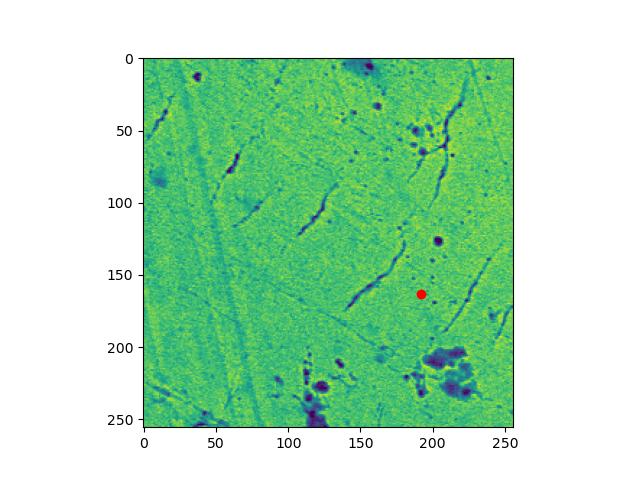

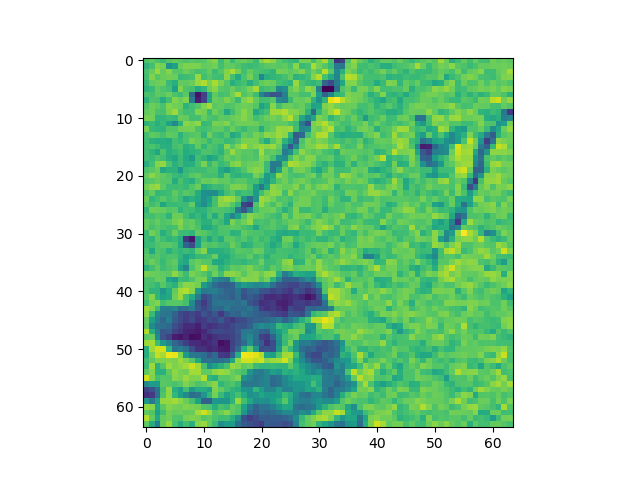

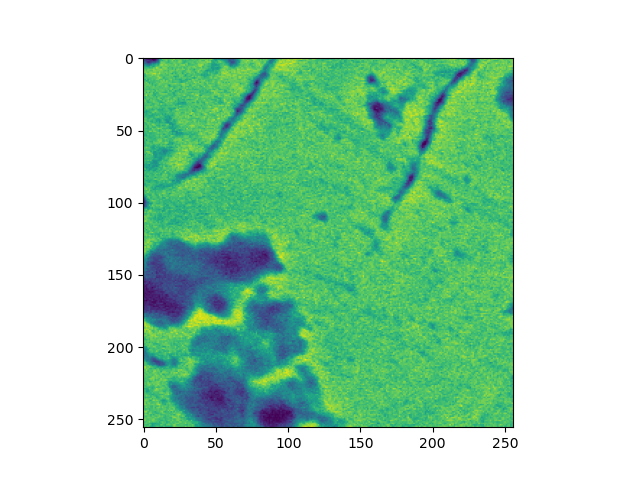

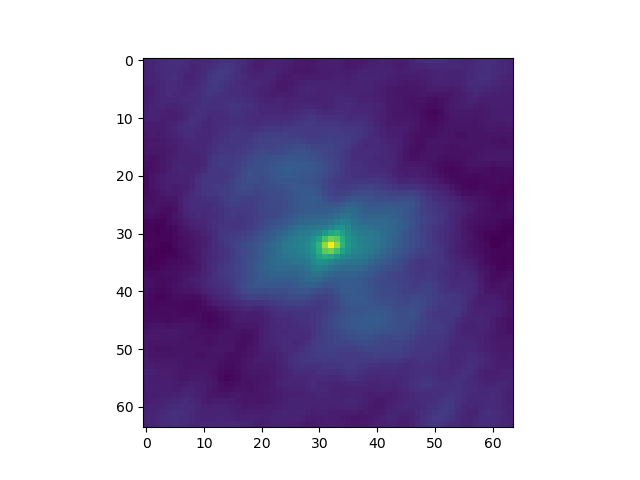

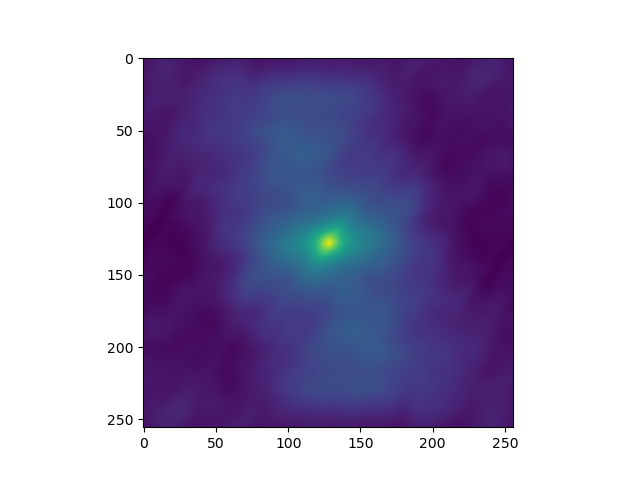

In [201]:
img, meta = take_image()
(xix, yix), optpos, ratio, acdata = find_ac_position(img, meta)
phenom.MoveTo(optpos)
phenom.SetHFW(phenom.GetHFW()/ratio)
newimg, newmeta = take_image()

plt.figure()
plt.imshow(img)

plt.plot([xix], [yix], 'ro')

plt.figure()
plt.imshow(img[yix:yix + 64, xix:xix + 64])

plt.figure()
plt.imshow(newimg)
plt.figure()
plt.imshow(auto_correlation(img[yix:yix + 64, xix:xix + 64]))

plt.figure()
plt.imshow(auto_correlation(newimg))

In [204]:
def optimum_stig_x(st):
    """ 
    Returns the astigmatism coefficient of a Zernike polynomial fitted to the autocorrelation data
    at the given stigmate st.

    Parameter st: a tuple (x, y) for the x-stigmate and y-stigmate
    """

    phenom.SetSemStigmate(ppi.Position(st[0], 0))

    if image_counter[0] % 10 == 0:
        phenom.SemAutoContrastBrightness()
    img_array, _ = take_image() # takes an image of the current location
    image_counter[0] += 1

    # blurred_img = cv2.GaussianBlur(img_array, (9, 9), 0)
    acdata = auto_correlation(img_array) # calculates the autocorrelation for the image
    filtered_acdata = remove_background_autocorr(acdata) # removes the background of the autocorrelation

    result = incoh_psf_fit(filtered_acdata, 1, 1, 1) # fits the data

    plt.figure()
    plt.subplot(1, 3, 1)
    plt.imshow(acdata)
    plt.subplot(1, 3, 2)
    plt.imshow(filtered_acdata)
    plt.subplot(1, 3, 3)
    plt.imshow(result.best_fit)

    return np.sqrt(result.best_values['xstig'] ** 2 + result.best_values['ystig'] ** 2) #+ result.best_values['defocus']


def optimum_stig_y(st):
    """ 
    Returns the astigmatism coefficient of a Zernike polynomial fitted to the autocorrelation data
    at the given stigmate st.

    Parameter st: a tuple (x, y) for the x-stigmate and y-stigmate
    """

    phenom.SetSemStigmate(ppi.Position(0, st[0]))

    if image_counter[0] % 10 == 0:
        phenom.SemAutoContrastBrightness()
    img_array, _ = take_image() # takes an image of the current location
    image_counter[0] += 1

    # blurred_img = cv2.GaussianBlur(img_array, (9, 9), 0)
    acdata = auto_correlation(img_array) # calculates the autocorrelation for the image
    filtered_acdata = remove_background_autocorr(acdata) # removes the background of the autocorrelation

    result = incoh_psf_fit(filtered_acdata, 1, 1, 1) # fits the data

    plt.figure()
    plt.subplot(1, 3, 1)
    plt.imshow(acdata)
    plt.subplot(1, 3, 2)
    plt.imshow(filtered_acdata)
    plt.subplot(1, 3, 3)
    plt.imshow(result.best_fit)

    return np.sqrt(result.best_values['xstig'] ** 2 + result.best_values['ystig'] ** 2) #+ result.best_values['defocus']


def auto_stig(xst_val_min, xst_val_max, yst_val_min, yst_val_max):
    """
    Determines the stigmate values corresponding to a focused image using bayesian optimization. 
    Sets the working distance to the value corresponding to a focused image after minimization.

    Parameter xst_val_min: the minimum x-stigmate (float) that is considered when minimizing
    Parameter xst_val_max: the maximum x-stigmate distance (float) that is considered when minimizing
    Parameter yst_val_min: the minimum y-stigmate distance (float) that is considered when minimizing
    Parameter yst_val_max: the maximum y-stigmate distance (float) that is considered when minimizing
    """

    res_x = gp_minimize(optimum_stig_x, 
                      [(xst_val_min, xst_val_max)], 
                      acq_func = "EI", 
                      n_calls = 20, 
                      n_initial_points = 5, 
                      verbose = False, 
                      random_state = 1234) 
    
    res_y = gp_minimize(optimum_stig_y, 
                      [(yst_val_min, yst_val_max)], 
                      acq_func = "EI", 
                      n_calls = 20, 
                      n_initial_points = 5, 
                      verbose = False, 
                      random_state = 1234) 

    print(res_x.x[0], res_y.x[0])
    phenom.SetSemStigmate(ppi.Position(res_x.x[0], res_y.x[0]))

    return res_x.x[0], res_y.x[0]

C:\Users\ThermoFisher\AppData\Roaming\Python\Python311\site-packages\uncertainties\core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")
C:\Users\ThermoFisher\AppData\Roaming\Python\Python311\site-packages\uncertainties\core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")
C:\Users\ThermoFisher\AppData\Roaming\Python\Python311\site-packages\uncertainties\core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")
C:\Users\ThermoFisher\AppData\Roaming\Python\Python311\site-packages\uncertainties\core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected res

0.02833637294960195 0.03890607971282982


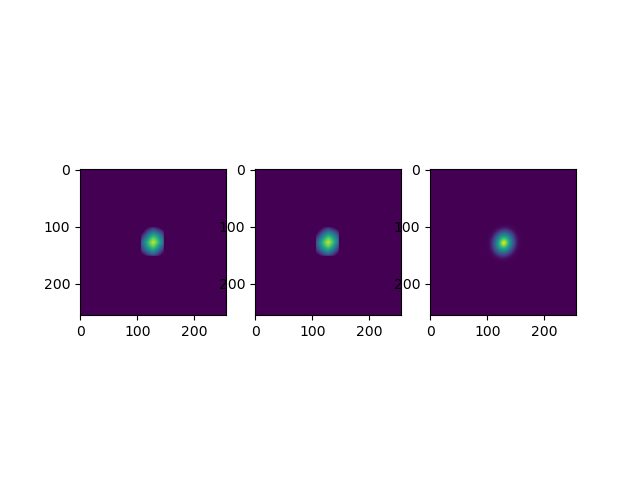

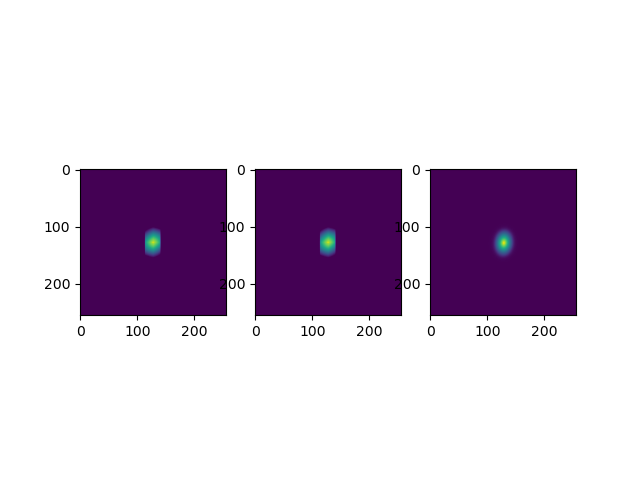

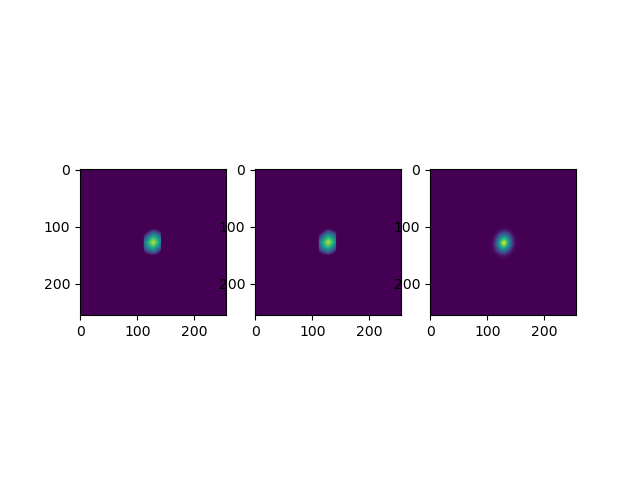

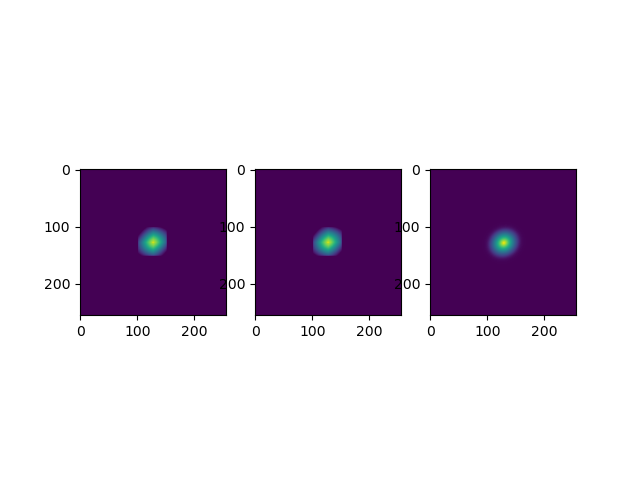

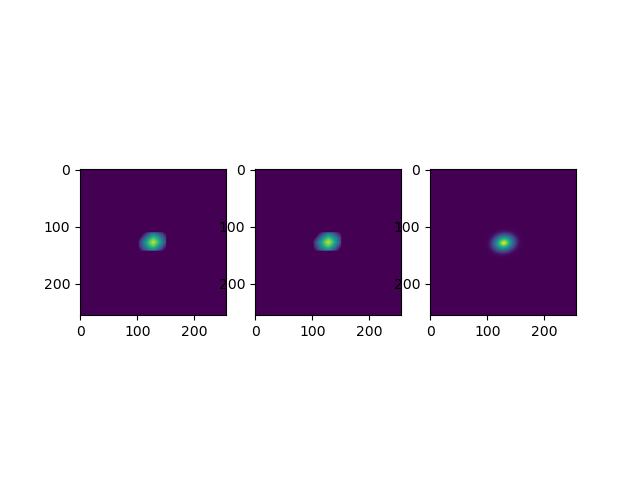

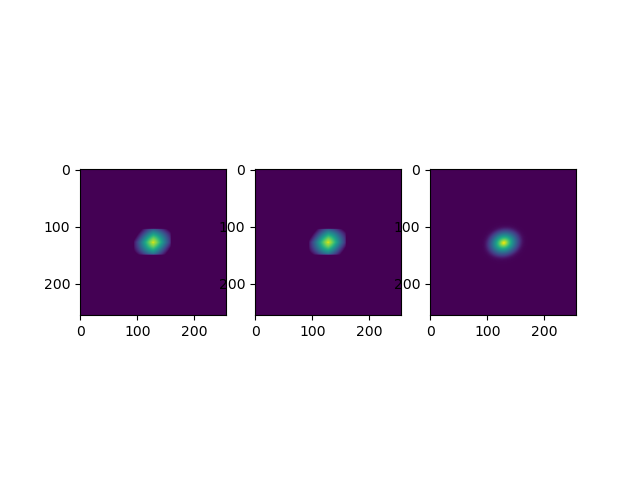

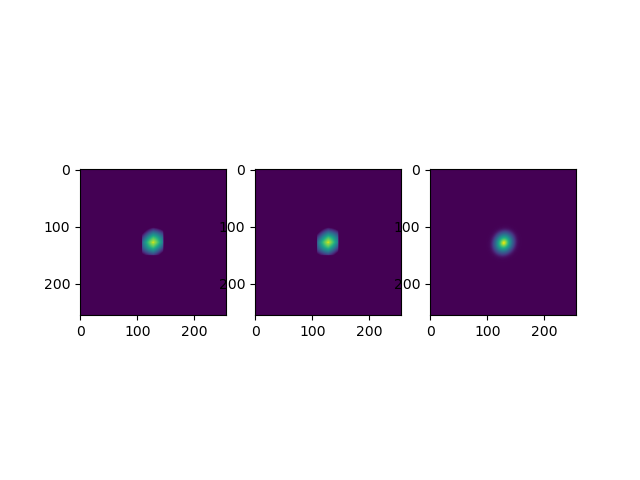

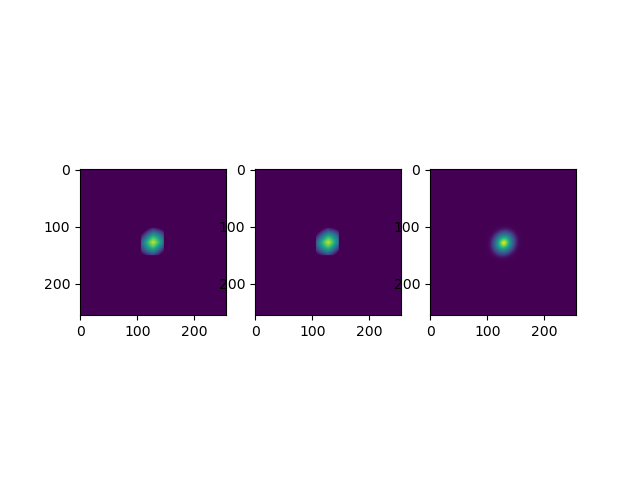

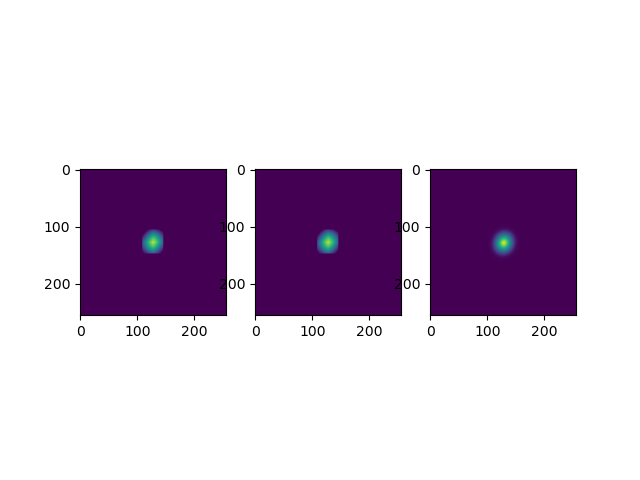

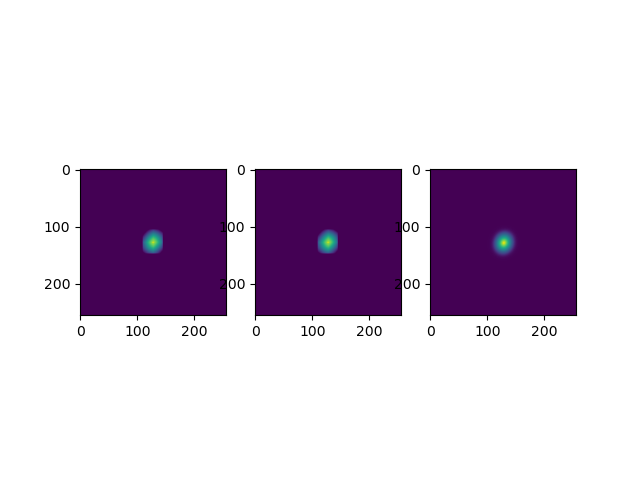

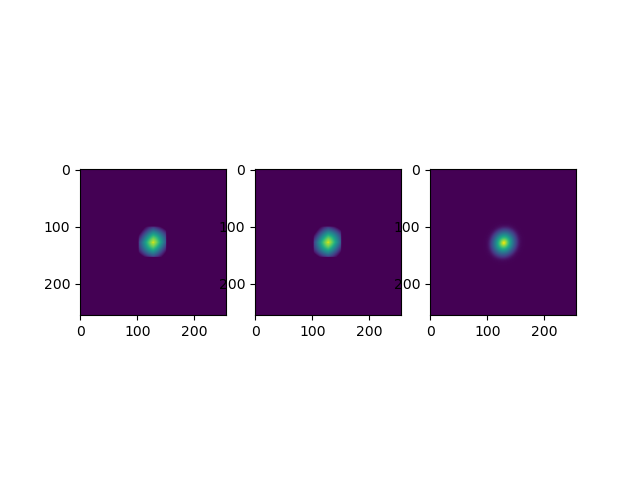

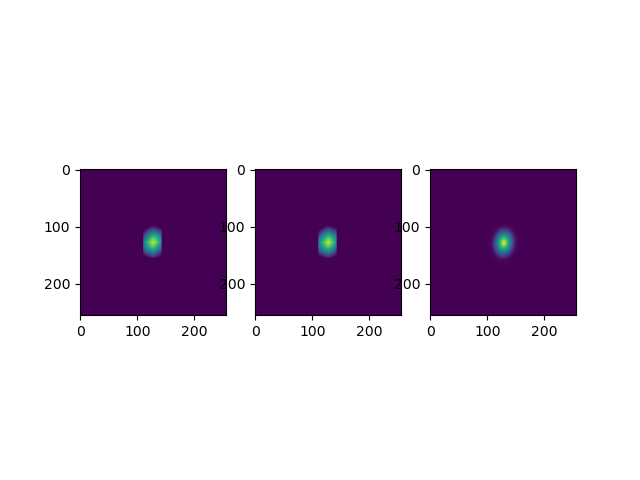

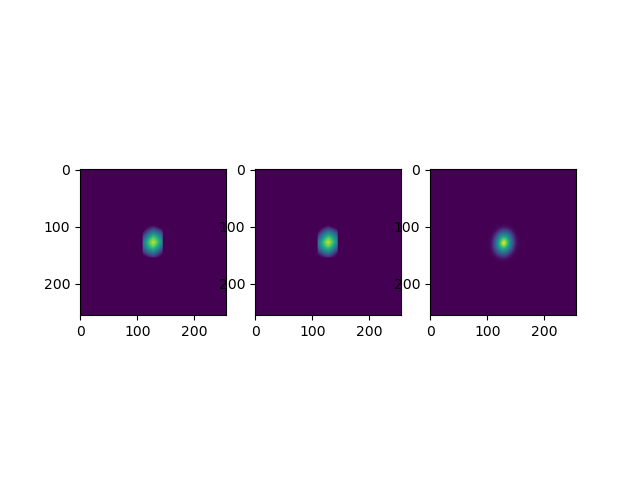

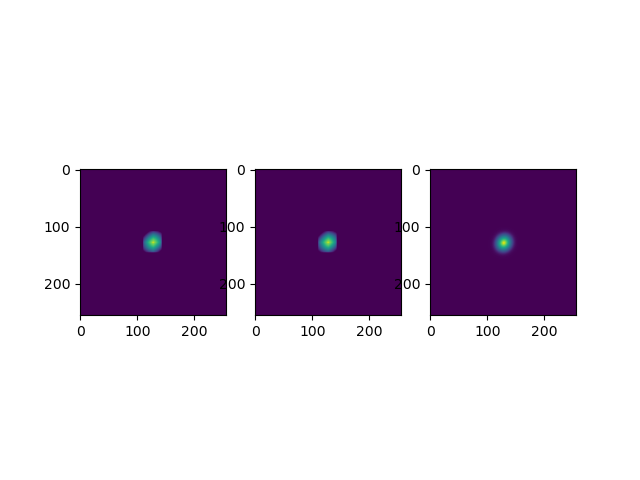

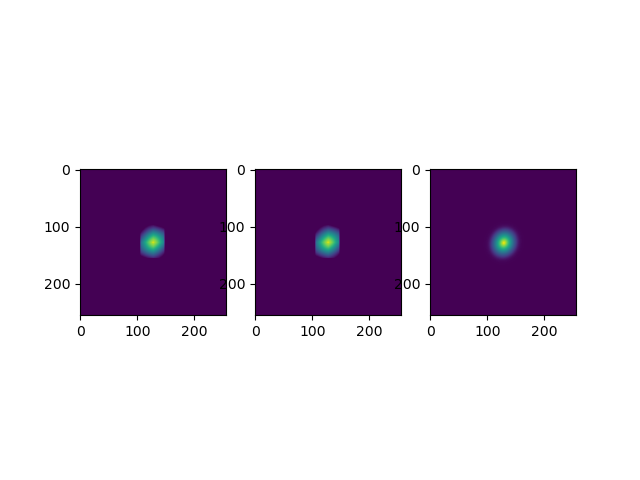

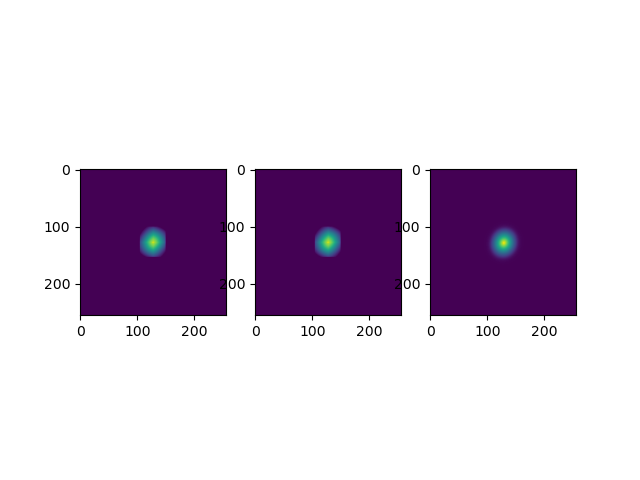

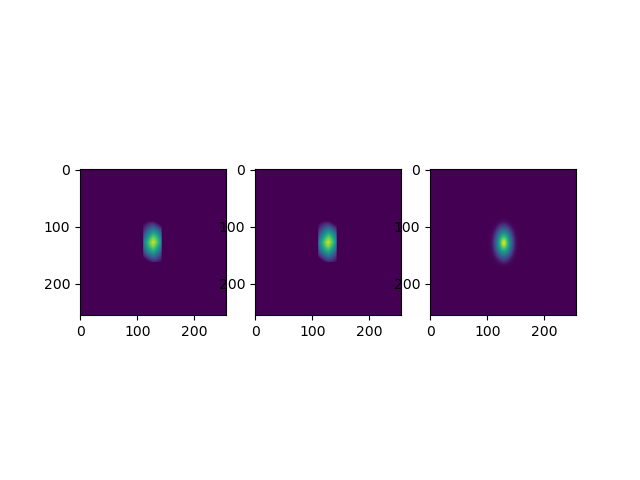

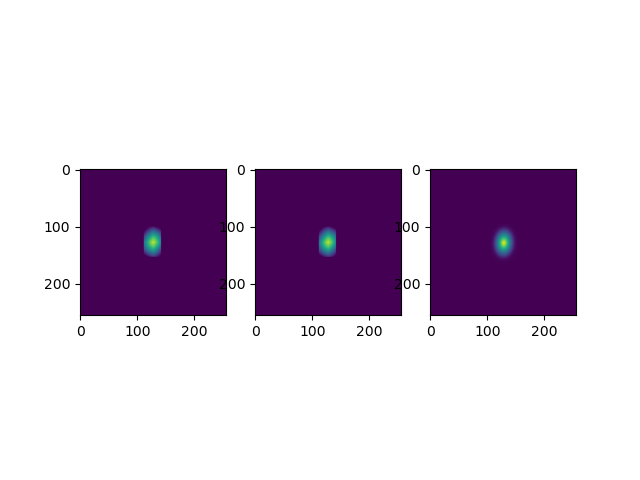

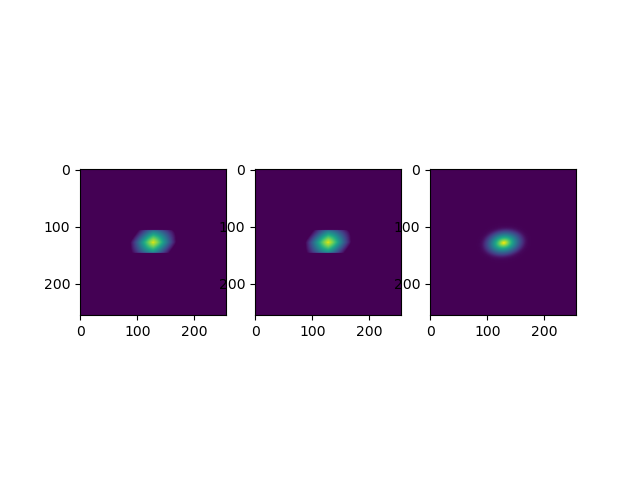

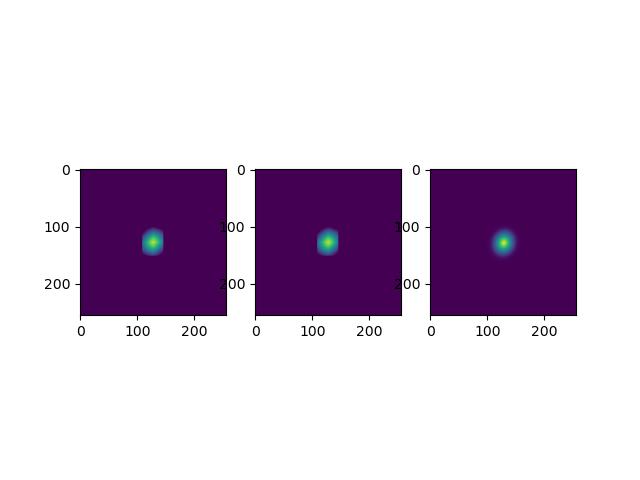

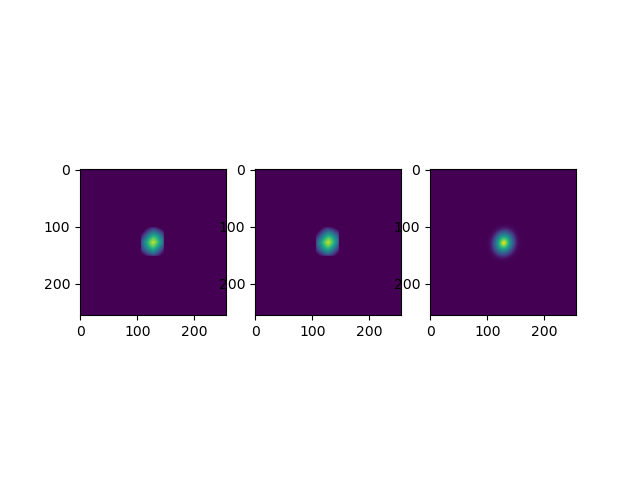

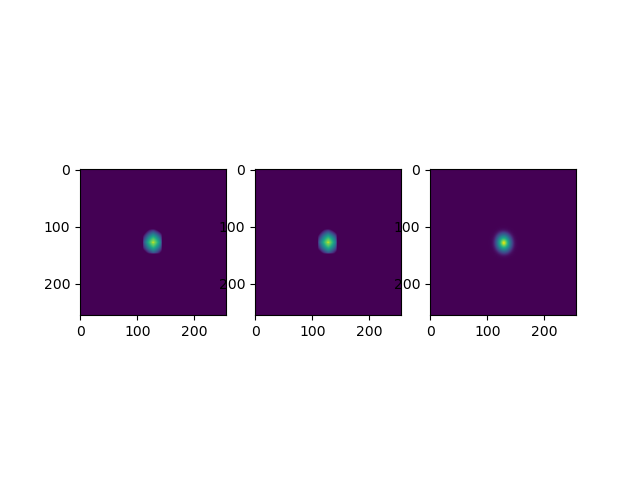

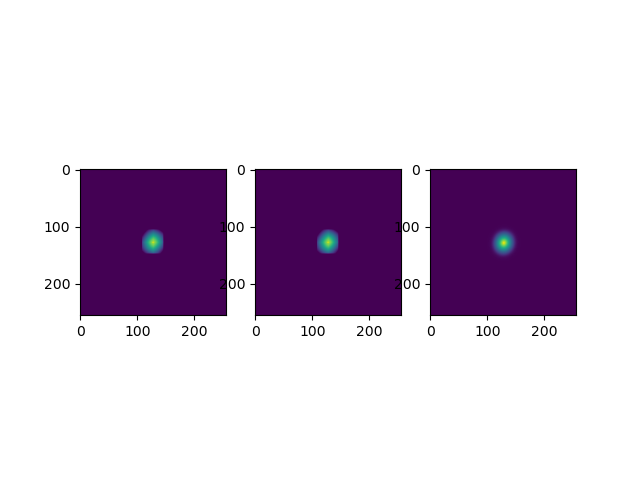

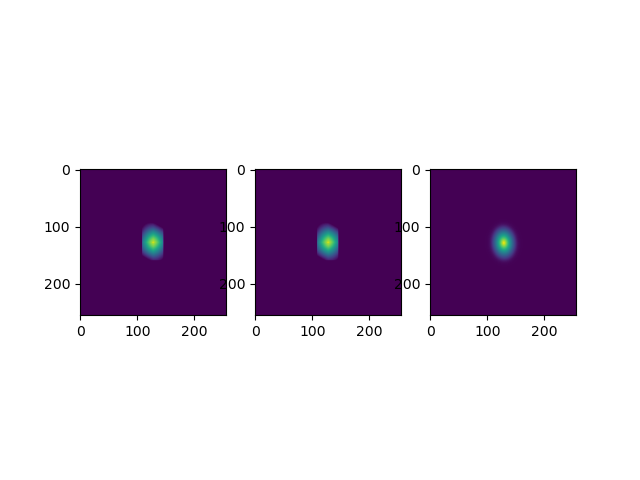

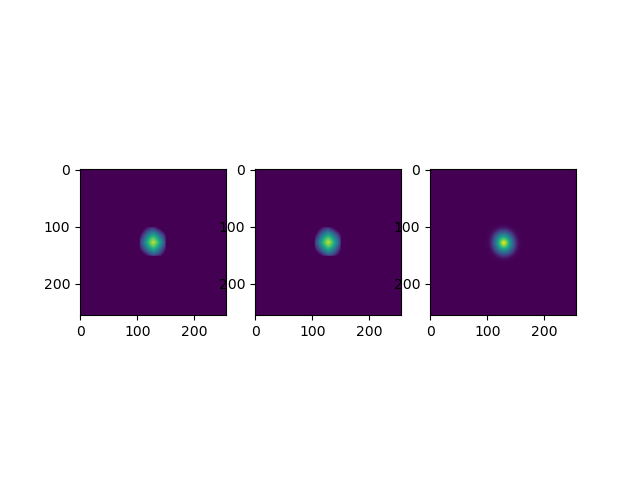

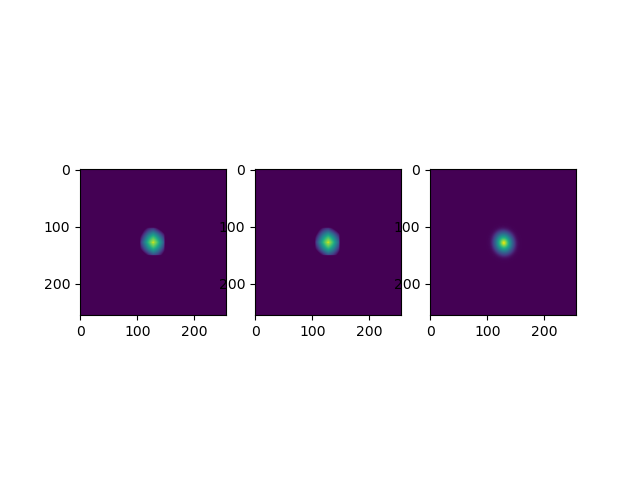

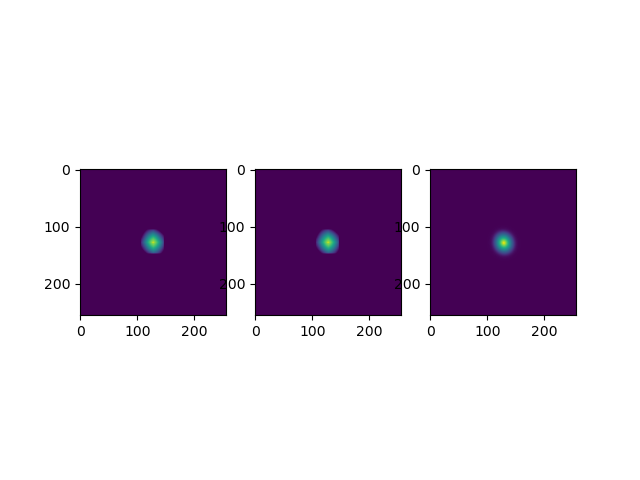

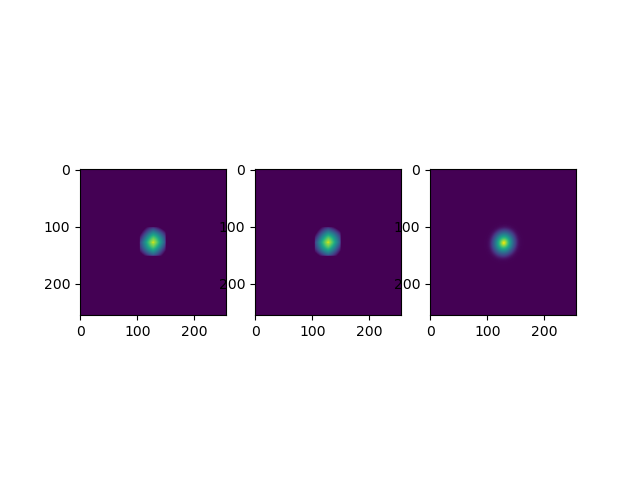

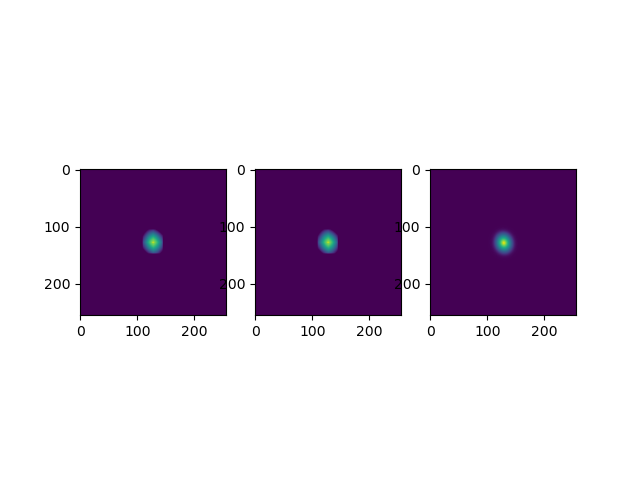

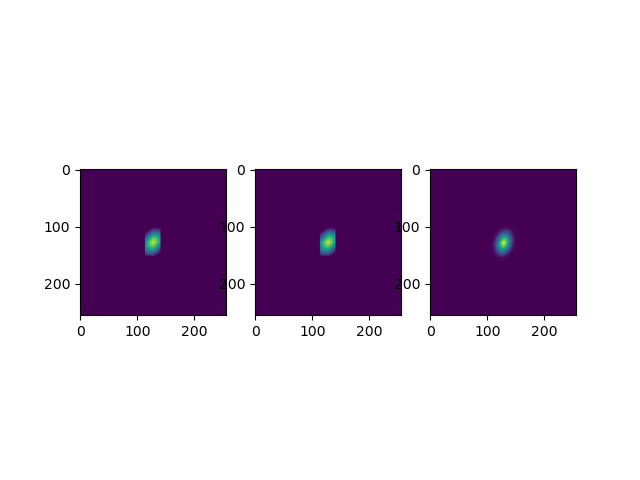

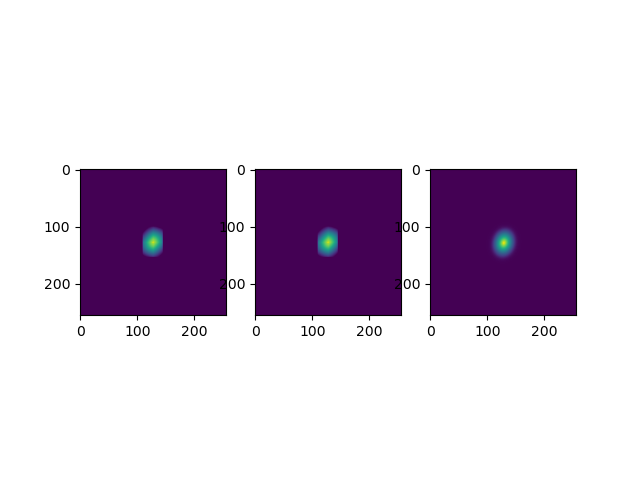

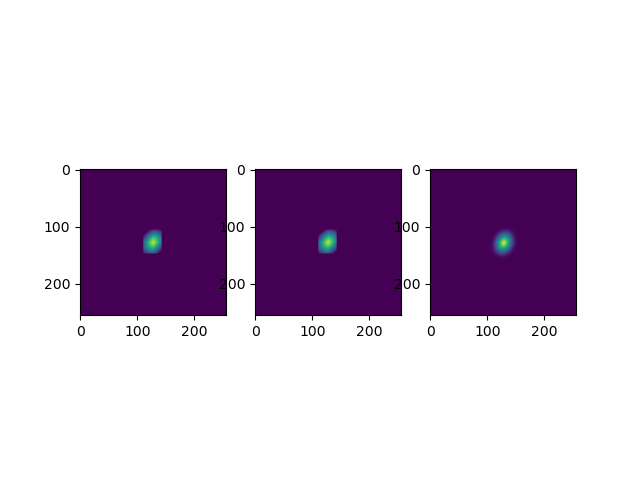

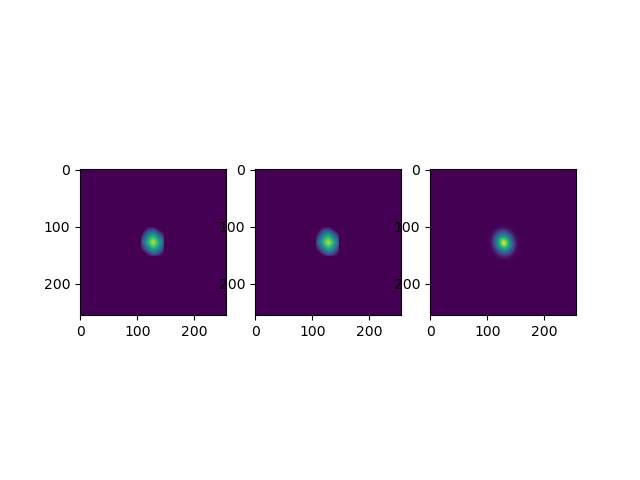

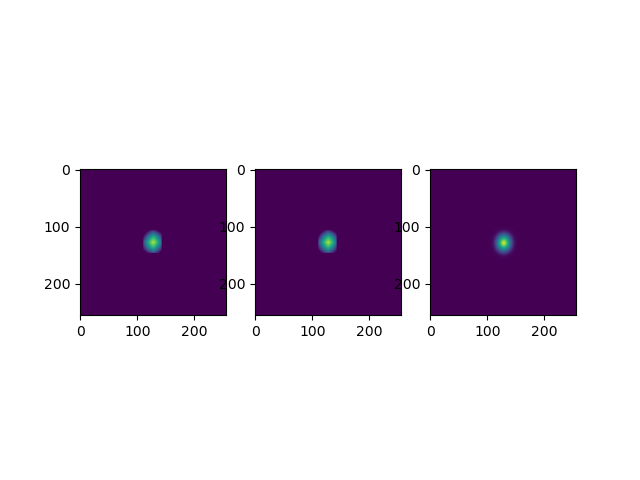

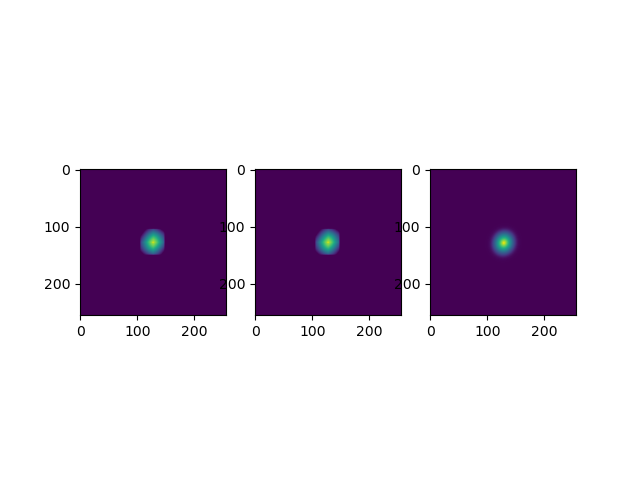

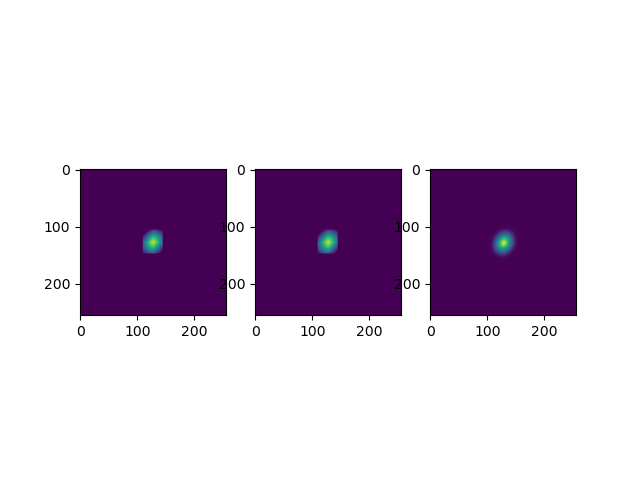

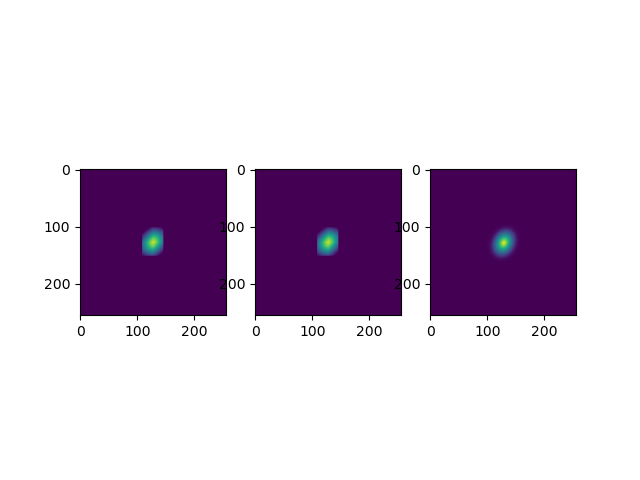

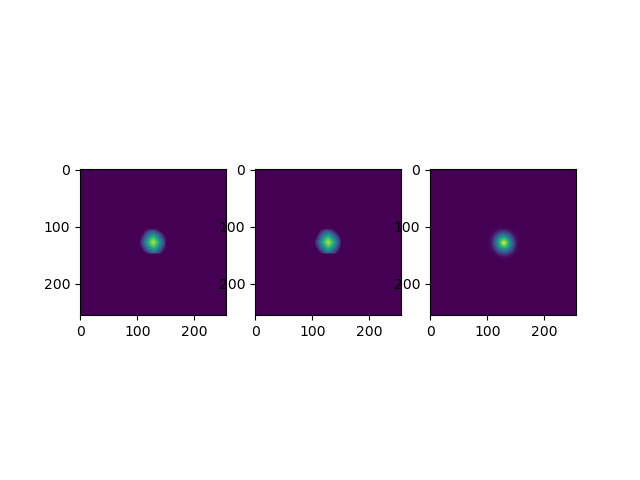

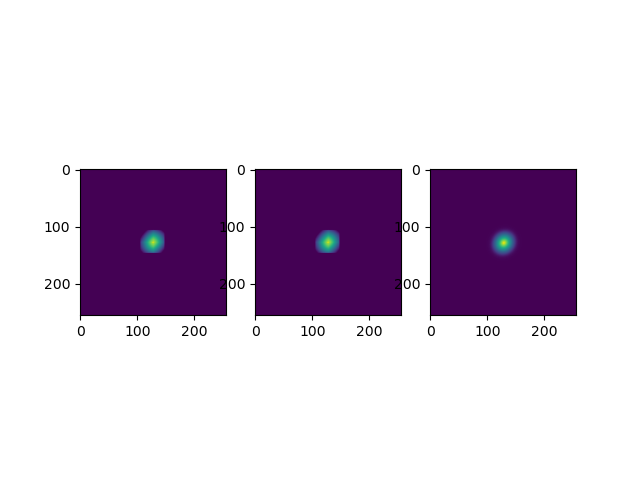

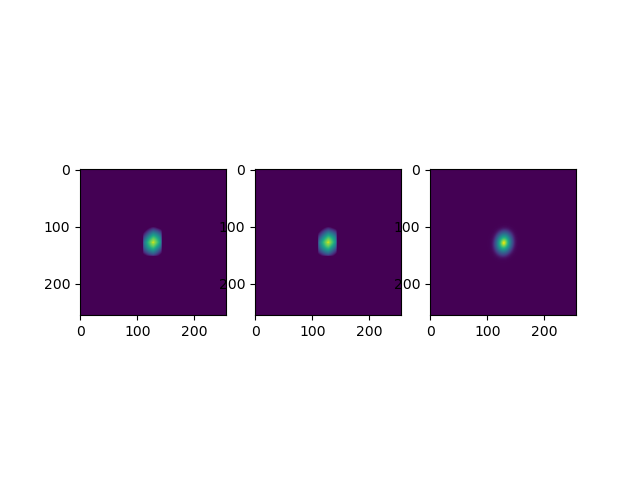

In [206]:
image_counter = [0]
x, y = auto_stig(xst_val_min, xst_val_max, yst_val_min, yst_val_max)

In [ ]:
image_counter = [0]

def thingy(wd_val_min, wd_val_max, xst_val_min, xst_val_max, yst_val_min, yst_val_max):
    phenom.SetHFW(ppi.MagnificationToFieldWidth(10000, 0.52))
    curr = auto_focus(wd_val_min, wd_val_max)
    reposition_v2()

    best_wd = 0

    for magnification in [20000, 40000]:
        phenom.SetHFW(ppi.MagnificationToFieldWidth(magnification, 0.52))
        best_wd = auto_focus(curr - (1 / 1000), curr + (1 / 1000))
        # reposition_v2()

    phenom.SetSemWD(best_wd - 0.00015) # sets the wd to slightly not optimal
    phenom.SetHFW(ppi.MagnificationToFieldWidth(100000, 0.52))
    x, y = auto_stig(xst_val_min, xst_val_max, yst_val_min, yst_val_max)
    phenom.SetSemWD(best_wd)

    print('stig', x, y)

    for r in range(2):
        phenom.SetHFW(ppi.MagnificationToFieldWidth(80000, 0.52))
        best_wd = auto_focus(curr - (1 / 1000), curr + (1 / 1000))

        phenom.SetSemWD(best_wd - 0.000015) # sets the wd to slightly not optimal
        phenom.SetHFW(ppi.MagnificationToFieldWidth(100000, 0.52))
        auto_stig(x - (0.1 / 20), x + (0.1 / 20), y - (0.1 / 20), y + (0.1 / 20))
    
    phenom.SetSemWD(best_wd)

thingy(wd_val_min, wd_val_max, xst_val_min, xst_val_max, yst_val_min, yst_val_max)

In [200]:
phenom.SemAutoContrastBrightness()
img, _ = take_image()
img_array = np.array(img) # converts image into an array
np.save(f"more_stig\\nn1.py", img_array)

first pic: not bad

second pic --> zoomed in section of first pic: forgot to unoptimize wd before stig, took again, worse after unoptimizing wd

third pic: had to play around to find a good unoptimized wd before could get a decent stig

fourth pic: first stig not bad, zoomed in to 120k and reoptimized and even better

fifth pic (stripes): couldnt get good stig --> acs all pretty small regardless of wd

sixth pic (stripes): changing wd only improved one of the stig values

seventh pic (stripes): stripes possibly messing it up too i think -> only one stig value decent 

eighth pic (dark sploth, not many features): not good :(

ninth pic: blurring worked when wd didnt?? -> some of the gradient cut offs werent great tho, gonna take data and try to fix

- interesting that changing the wd sometimes only improves one direction of stig --> try blurring on a optimized wd image to see what happens?